In [1]:
import pandas as pd
import numpy as np

# 1. Đọc dữ liệu
print("Đang đọc dữ liệu...")
orders = pd.read_csv('orders.csv')
prior = pd.read_csv('order_products__prior.csv')

# 2. LÀM SẠCH BẢNG ORDERS (Tạo silver_orders)
# Xử lý NULL: Giữ nguyên NULL, thêm cờ is_first_order = 1 cho đơn đầu tiên
orders['is_first_order'] = np.where(orders['days_since_prior_order'].isnull(), 1, 0)
# Xóa các dòng không có user_id (nếu có)
orders_clean = orders.dropna(subset=['user_id', 'order_id'])
# Đảm bảo kiểu dữ liệu số nguyên cho các cột ID
orders_clean['order_id'] = orders_clean['order_id'].astype(int)
orders_clean['user_id'] = orders_clean['user_id'].astype(int)

# 3. LÀM SẠCH BẢNG ORDER_PRODUCTS (Tạo silver_order_products)
prior_clean = prior.dropna(subset=['order_id', 'product_id'])
prior_clean = prior_clean.drop_duplicates() # Xóa trùng lặp
prior_clean['order_id'] = prior_clean['order_id'].astype(int)
prior_clean['product_id'] = prior_clean['product_id'].astype(int)

# 4. Lưu thành file Silver
orders_clean.to_csv('silver_orders.csv', index=False)
prior_clean.to_csv('silver_order_products.csv', index=False)

print("Đã làm sạch xong!")
print("Số dòng orders ban đầu:", len(orders), "-> Sau khi sạch:", len(orders_clean))
print("Số dòng order_products ban đầu:", len(prior), "-> Sau khi sạch:", len(prior_clean))

Đang đọc dữ liệu...
Đã làm sạch xong!
Số dòng orders ban đầu: 173155 -> Sau khi sạch: 173155
Số dòng order_products ban đầu: 1630163 -> Sau khi sạch: 1630163


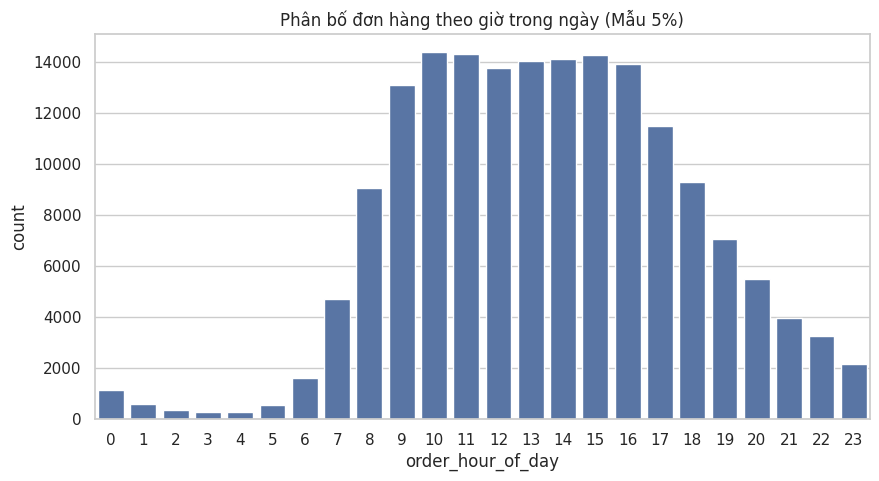

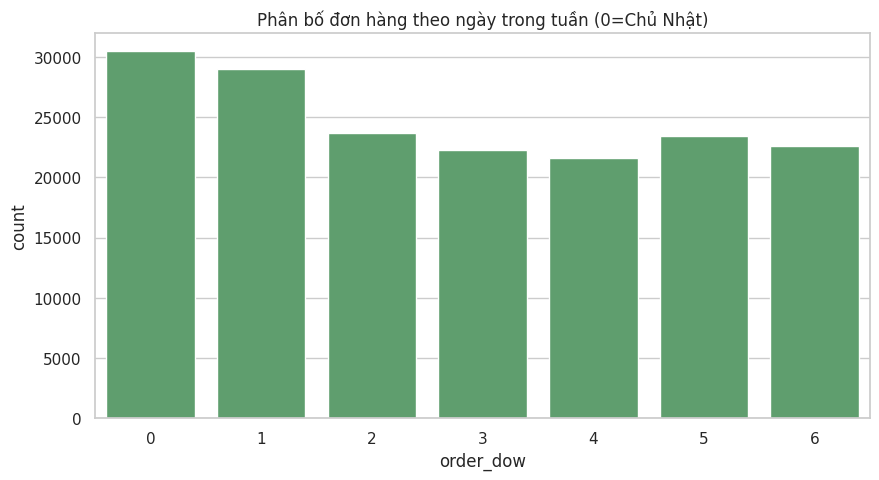

/tmp/ipykernel_763/751653505.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.values, y=top_10.index, palette='viridis')


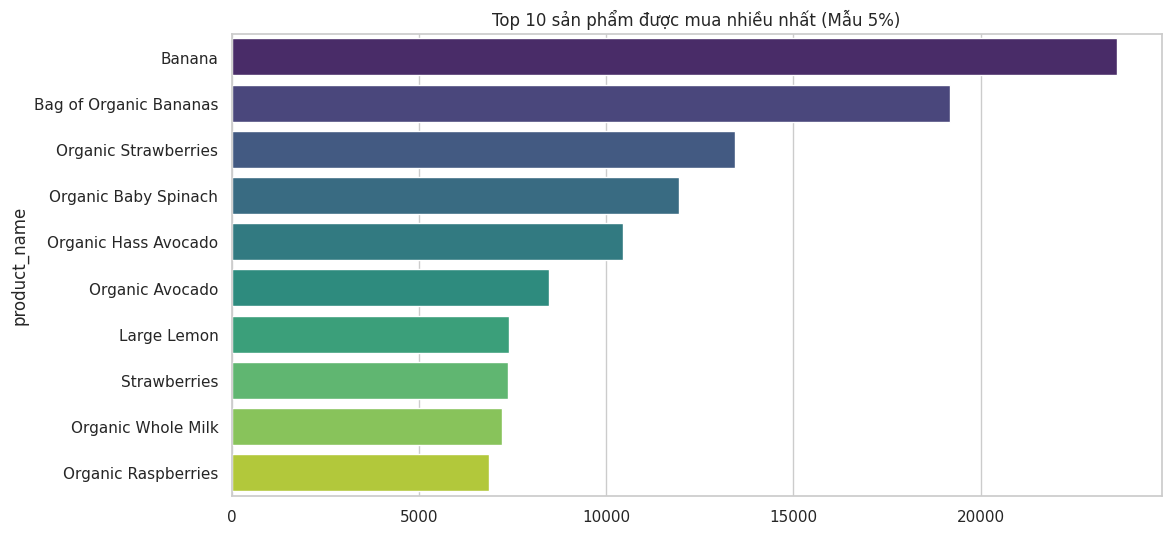

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu sạch
orders_clean = pd.read_csv('silver_orders.csv')
prior_clean = pd.read_csv('silver_order_products.csv')
products = pd.read_csv('products.csv')

# Cài đặt giao diện
sns.set_theme(style="whitegrid")

# --- BIỂU ĐỒ 1: Đơn hàng theo giờ ---
plt.figure(figsize=(10, 5))
sns.countplot(data=orders_clean, x='order_hour_of_day', color='#4C72B0')
plt.title('Phân bố đơn hàng theo giờ trong ngày (Mẫu 5%)')
plt.savefig('bieu_do_gio.png')
plt.show()

# --- BIỂU ĐỒ 2: Đơn hàng theo ngày ---
plt.figure(figsize=(10, 5))
sns.countplot(data=orders_clean, x='order_dow', color='#55A868')
plt.title('Phân bố đơn hàng theo ngày trong tuần (0=Chủ Nhật)')
plt.savefig('bieu_do_ngay.png')
plt.show()

# --- BIỂU ĐỒ 3: Top 10 sản phẩm bán chạy ---
top_products = prior_clean.merge(products, on='product_id')
top_10 = top_products['product_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_10.values, y=top_10.index, palette='viridis')
plt.title('Top 10 sản phẩm được mua nhiều nhất (Mẫu 5%)')
plt.savefig('bieu_do_top_san_pham.png')
plt.show()